# Week 2 — Task 2: First full 100%-bracket run, verify learning curve looks sane

Covers tracker sub-tasks 2.1–2.4:

| Task ID | Sub-task |
|---|---|
| 2.1 | Launch the 100%-bracket training run (seed=1) |
| 2.2 | Plot the training/validation loss curves |
| 2.3 | Sanity-check the final Dice score is plausible (on the untouched TEST set) |
| 2.4 | Report the result to Sebastian and log in decisions.md |

Self-contained, same building blocks as the Week 2 Task 1 notebook (`set_seed`,
`build_train_transform`/`build_eval_transform`, `collate_kvasir_samples`,
`combined_loss`, `evaluate_val_dice`, `save_checkpoint`/`load_checkpoint`) — kept
consistent rather than re-derived, so a difference in results is a real finding, not
a code drift artifact.

**Before running Task 2.3:** `configs/eval.yaml`'s `boundary_iou.dilation_px` is still
`null` (open TODO, same one flagged since Week 1) — `src/evaluate.py` refuses to run
without it. This notebook uses `src/evaluate.py`'s own `--dilation-px`-equivalent
override (`EVAL_DILATION_PX` below) for this one-off run, rather than deciding the
real config value on your behalf. Confirm that value with Sebastian before Week 3.

In [1]:
from pathlib import Path
import random
import subprocess
import sys
import time
from datetime import date

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import yaml
from albumentations.pytorch import ToTensorV2
from PIL import Image
from torch.utils.data import DataLoader

%matplotlib inline

REPO_ROOT = Path.cwd().parent  # assumes notebooks/
sys.path.insert(0, str(REPO_ROOT / "src"))

from dataset import KvasirSegDataset  # noqa: E402
from metrics import dice as dice_metric  # noqa: E402
from unet import UNet  # noqa: E402

DATA_ROOT_CANDIDATES = [REPO_ROOT / "data" / "kvasir-seg", REPO_ROOT / "data" / "kvasir-seg" / "Kvasir-SEG"]
DATA_ROOT = next((c for c in DATA_ROOT_CANDIDATES if (c / "images").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError(f"Couldn't find images/ under any of {DATA_ROOT_CANDIDATES}.")

SPLITS_DIR = REPO_ROOT / "data" / "splits"
DECISIONS_MD = REPO_ROOT / "decisions.md"
CHECKPOINTS_DIR = REPO_ROOT / "checkpoints"
CHECKPOINTS_DIR.mkdir(exist_ok=True)
PRED_DIR = REPO_ROOT / "results" / "unet_preds" / "100pct_seed1"
PRED_DIR.mkdir(parents=True, exist_ok=True)

with open(REPO_ROOT / "configs" / "unet_base.yaml") as f:
    UNET_CFG = yaml.safe_load(f)
with open(REPO_ROOT / "configs" / "eval.yaml") as f:
    EVAL_CFG = yaml.safe_load(f)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

BRACKET = "100pct"
SEED = 1  # tracker sub-task 2.1 specifies seed=1 for this first full run
EVAL_DILATION_PX = 2  # override for configs/eval.yaml's still-null boundary_iou.dilation_px —
                       # matches metrics.py's own DEFAULT_DILATION_PX; NOT a substitute for the
                       # real joint decision still owed in decisions.md

print(f"Device: {DEVICE}  Bracket: {BRACKET}  Seed: {SEED}")
results_log = {}

Device: mps  Bracket: 100pct  Seed: 1


## Task 2.1 — Launch the 100%-bracket training run

Same seeding/augmentation/loss/checkpointing machinery as Task 1, just pointed at
`train_100.txt` instead of `train_10.txt`, and `seed=1` instead of `seed=0`. This is
your first real run on all ~700 training images — expect it to take meaningfully
longer than the Task 1 smoke run; the tracker estimates "30-90 min, mostly waiting"
(on GPU/Colab — could run longer on this Mac mini's `mps` backend).

In [2]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def build_train_transform() -> A.Compose:
    return A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=35, p=0.5),
            A.Affine(scale=(0.85, 1.15), p=0.5),
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ]
    )


def build_eval_transform() -> A.Compose:
    return A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])


def collate_kvasir_samples(batch: list) -> dict:
    images = torch.stack([s.image for s in batch], dim=0)
    masks = torch.stack([s.mask for s in batch], dim=0)
    image_ids = [s.image_id for s in batch]
    return {"image": images, "mask": masks, "image_id": image_ids}


def dice_loss(logits, target, eps: float = 1e-6):
    probs = torch.sigmoid(logits)
    probs_flat = probs.flatten(1)
    target_flat = target.flatten(1)
    intersection = (probs_flat * target_flat).sum(dim=1)
    denom = probs_flat.sum(dim=1) + target_flat.sum(dim=1)
    return 1.0 - ((2 * intersection + eps) / (denom + eps)).mean()


bce_loss = nn.BCEWithLogitsLoss()


def combined_loss(logits, target):
    return bce_loss(logits, target) + dice_loss(logits, target)


@torch.no_grad()
def evaluate_val_dice(model, val_loader, device) -> float:
    model.eval()
    dice_scores = []
    for batch in val_loader:
        images = batch["image"].to(device)
        logits = model(images)
        preds = (torch.sigmoid(logits) > 0.5).squeeze(1).cpu().numpy().astype(np.uint8)
        gts = batch["mask"].numpy().astype(np.uint8)
        for pred, gt in zip(preds, gts):
            dice_scores.append(dice_metric(pred, gt))
    model.train()
    return float(np.mean(dice_scores))


def save_checkpoint(path, model, optimizer, epoch, best_val_dice, seed, bracket):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
         "epoch": epoch, "best_val_dice": best_val_dice, "seed": seed, "bracket": bracket},
        path,
    )


def load_checkpoint(path, model, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer is not None and "optimizer_state_dict" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    return ckpt


print("Building blocks ready (same as Task 1 notebook).")

Building blocks ready (same as Task 1 notebook).


In [3]:
set_seed(SEED)

MAX_EPOCHS = 100
PATIENCE = 10  # same default as Task 1 — still an open decisions.md TODO, see there
BATCH_SIZE = 8

bracket_cfg = next(b for b in UNET_CFG["brackets"] if b["name"] == BRACKET)
train_split = REPO_ROOT / bracket_cfg["split_file"]
val_split = SPLITS_DIR / "val.txt"
resize = tuple(UNET_CFG["input"]["resize"])

train_dataset = KvasirSegDataset(str(DATA_ROOT), str(train_split), resize=resize, transform=build_train_transform())
val_dataset = KvasirSegDataset(str(DATA_ROOT), str(val_split), resize=resize, transform=build_eval_transform())

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_kvasir_samples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_kvasir_samples)

model = UNet(in_channels=3, out_channels=1, base_channels=UNET_CFG["model"]["base_channels"],
             depth=UNET_CFG["model"]["depth"]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=UNET_CFG["training"]["lr"])

run_name = f"{BRACKET}_seed{SEED}"
best_ckpt_path = CHECKPOINTS_DIR / f"unet_{run_name}_best.pt"
last_ckpt_path = CHECKPOINTS_DIR / f"unet_{run_name}_last.pt"

best_val_dice = -1.0
epochs_without_improvement = 0
history = []

print(f"Run: bracket={BRACKET} seed={SEED} device={DEVICE} "
      f"train_images={len(train_dataset)} val_images={len(val_dataset)}")
print("This is the real 100%-bracket run — expect this cell to take a while.\n")

t_start_total = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.perf_counter()
    model.train()
    running_loss = 0.0
    n_batches = 0

    for batch in train_loader:
        images = batch["image"].to(DEVICE)
        targets = batch["mask"].unsqueeze(1).float().to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = combined_loss(logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        n_batches += 1

    train_loss = running_loss / n_batches
    val_dice = evaluate_val_dice(model, val_loader, DEVICE)
    epoch_time = time.perf_counter() - t0
    history.append({"epoch": epoch, "train_loss": train_loss, "val_dice": val_dice, "time_s": epoch_time})

    improved = val_dice > best_val_dice
    if improved:
        best_val_dice = val_dice
        epochs_without_improvement = 0
        save_checkpoint(best_ckpt_path, model, optimizer, epoch, best_val_dice, SEED, BRACKET)
    else:
        epochs_without_improvement += 1

    save_checkpoint(last_ckpt_path, model, optimizer, epoch, best_val_dice, SEED, BRACKET)

    marker = "*" if improved else " "
    print(f"Epoch {epoch:3d}/{MAX_EPOCHS}  train_loss={train_loss:.4f}  "
          f"val_dice={val_dice:.4f}{marker}  best={best_val_dice:.4f}  "
          f"no_improve={epochs_without_improvement}  time={epoch_time:.1f}s")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: no val_dice improvement for {PATIENCE} epochs.")
        break

total_train_time = time.perf_counter() - t_start_total
print(f"\nDone in {total_train_time:.1f}s. Best val_dice={best_val_dice:.4f} -> {best_ckpt_path.relative_to(REPO_ROOT)}")

results_log["2.1"] = (
    f"PASS — trained {BRACKET}/seed{SEED} for {len(history)} epochs, best val_dice={best_val_dice:.4f}, "
    f"total wall-clock={total_train_time:.1f}s on {DEVICE}, no crashes."
)

Run: bracket=100pct seed=1 device=mps train_images=700 val_images=100
This is the real 100%-bracket run — expect this cell to take a while.

Epoch   1/100  train_loss=1.1810  val_dice=0.3874*  best=0.3874  no_improve=0  time=41.4s
Epoch   2/100  train_loss=1.0590  val_dice=0.4316*  best=0.4316  no_improve=0  time=37.3s
Epoch   3/100  train_loss=1.0089  val_dice=0.3831   best=0.4316  no_improve=1  time=37.4s
Epoch   4/100  train_loss=0.9746  val_dice=0.4534*  best=0.4534  no_improve=0  time=37.6s
Epoch   5/100  train_loss=0.9637  val_dice=0.4958*  best=0.4958  no_improve=0  time=37.9s
Epoch   6/100  train_loss=0.9265  val_dice=0.4953   best=0.4958  no_improve=1  time=37.9s
Epoch   7/100  train_loss=0.9322  val_dice=0.5127*  best=0.5127  no_improve=0  time=38.5s
Epoch   8/100  train_loss=0.9072  val_dice=0.4998   best=0.5127  no_improve=1  time=39.2s
Epoch   9/100  train_loss=0.8866  val_dice=0.5303*  best=0.5303  no_improve=0  time=36.7s
Epoch  10/100  train_loss=0.8799  val_dice=0.4647

## Task 2.2 — Plot the training/validation loss curves

Loss should trend down and roughly flatten. Val Dice should trend up. Flat-from-the-start
or diverging curves are the bugs this check is meant to catch, before Week 3's 12-run grid.

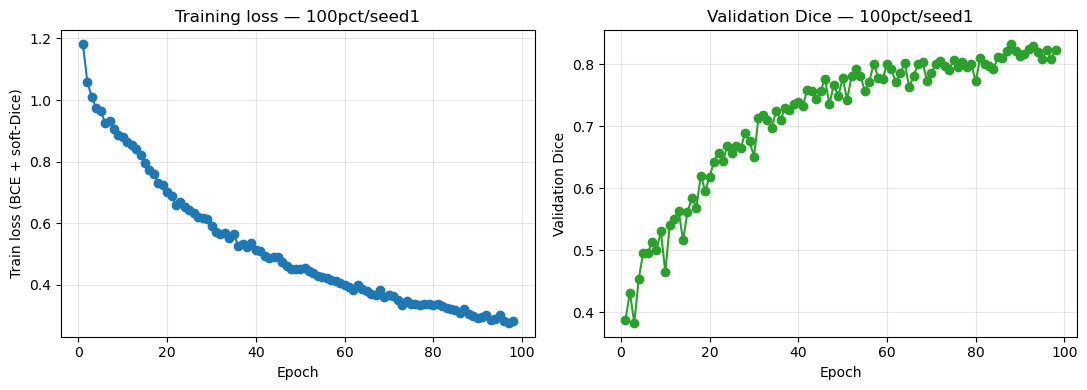

Loss dropped over the run: True  |  Val Dice rose overall: True
PASS — train_loss 1.1810 -> 0.2826, val_dice 0.3874 -> 0.8222 (best 0.8319) over 98 epochs. Curve shape looks like real learning.


In [4]:
epochs = [h["epoch"] for h in history]
train_losses = [h["train_loss"] for h in history]
val_dices = [h["val_dice"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, train_losses, marker="o")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Train loss (BCE + soft-Dice)")
axes[0].set_title(f"Training loss — {BRACKET}/seed{SEED}")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, val_dices, marker="o", color="tab:green")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation Dice")
axes[1].set_title(f"Validation Dice — {BRACKET}/seed{SEED}")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Cheap automated shape check, on top of your own eyeballing of the plot above.
loss_dropped = train_losses[-1] < train_losses[0]
dice_rose = val_dices[-1] > val_dices[0] if len(val_dices) > 1 else True
looks_sane = loss_dropped and dice_rose
print(f"Loss dropped over the run: {loss_dropped}  |  Val Dice rose overall: {dice_rose}")

results_log["2.2"] = (
    f"{'PASS' if looks_sane else 'WARN'} — train_loss {train_losses[0]:.4f} -> {train_losses[-1]:.4f}, "
    f"val_dice {val_dices[0]:.4f} -> {val_dices[-1]:.4f} (best {best_val_dice:.4f}) over {len(history)} epochs. "
    f"{'Curve shape looks like real learning.' if looks_sane else 'Curve looks flat/divergent — investigate before Week 3.'}"
)
print(results_log["2.2"])

## Task 2.3 — Sanity-check the final Dice score is plausible (on the TEST set)

This is deliberately NOT validation Dice again — it's the actual, untouched `test.txt`
split, scored the same way the real Week 3 results will be: run inference, write
predicted mask PNGs, then hand them to the shared `src/evaluate.py` (same harness
Sebastian's SAM 3 arm uses) rather than reimplementing scoring here.

In [5]:
# Reload the BEST checkpoint (not whatever's left in `model` from the last epoch) —
# the point of early stopping is that best != last.
best_model = UNet(in_channels=3, out_channels=1, base_channels=UNET_CFG["model"]["base_channels"],
                   depth=UNET_CFG["model"]["depth"]).to(DEVICE)
load_checkpoint(best_ckpt_path, best_model, map_location=DEVICE)
best_model.eval()

test_split = SPLITS_DIR / "test.txt"
test_dataset = KvasirSegDataset(str(DATA_ROOT), str(test_split), resize=resize, transform=build_eval_transform())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_kvasir_samples)

t0 = time.perf_counter()
n_written = 0
with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(DEVICE)
        logits = best_model(images)
        preds = (torch.sigmoid(logits) > 0.5).squeeze(1).cpu().numpy().astype(np.uint8)
        for image_id, pred in zip(batch["image_id"], preds):
            # evaluate.py expects predictions resized to native GT resolution, not the
            # fixed 256x256 training size — reload GT once here just to get its shape.
            gt_path = DATA_ROOT / "masks" / f"{image_id}.jpg"
            gt_native_shape = np.array(Image.open(gt_path).convert("L")).shape
            pred_img = Image.fromarray(pred * 255).resize(
                (gt_native_shape[1], gt_native_shape[0]), Image.NEAREST
            )
            pred_img.save(PRED_DIR / f"{image_id}.png")
            n_written += 1
inference_time = time.perf_counter() - t0

print(f"Wrote {n_written} predicted masks to {PRED_DIR.relative_to(REPO_ROOT)} in {inference_time:.1f}s "
      f"({inference_time / n_written * 1000:.1f} ms/image).")

Wrote 200 predicted masks to results/unet_preds/100pct_seed1 in 4.4s (22.1 ms/image).


In [6]:
# Hand off to the SHARED evaluate.py — same harness Sebastian's SAM 3 arm uses —
# rather than reimplementing scoring in this notebook. --dilation-px overrides the
# still-null configs/eval.yaml value for this one-off run only (does not edit the file).
cmd = [
    sys.executable, str(REPO_ROOT / "src" / "evaluate.py"),
    "--data-root", str(DATA_ROOT),
    "--split-file", str(test_split),
    "--pred-dir", str(PRED_DIR),
    "--arm", "unet",
    "--run-id", run_name,
    "--dilation-px", str(EVAL_DILATION_PX),
    "--no-append",  # this notebook's own scratch CSV, not the shared master one yet
    "--out-csv", str(REPO_ROOT / "results" / f"unet_{run_name}_per_image.csv"),
]
print("Running:", " ".join(cmd), "\n")
result = subprocess.run(cmd, capture_output=True, text=True, cwd=str(REPO_ROOT))
print(result.stdout)
if result.returncode != 0:
    print(result.stderr, file=sys.stderr)
    raise RuntimeError("evaluate.py failed — see stderr above.")

Running: /opt/anaconda3/bin/python /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/src/evaluate.py --data-root /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/data/kvasir-seg --split-file /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/data/splits/test.txt --pred-dir /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/results/unet_preds/100pct_seed1 --arm unet --run-id 100pct_seed1 --dilation-px 2 --no-append --out-csv /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/results/unet_100pct_seed1_per_image.csv 

Wrote 200 rows to /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/results/unet_100pct_seed1_per_image.csv (mode=w).
          dice: mean=0.8293  n=200
           iou: mean=0.7399  n=200
  boundary_iou: mean=0.1035  n=200
          hd95: mean=80.3528  n=199
     precision: mean=0.8485  n=200
        recall: mean=0.8615  n=200



In [7]:
import pandas as pd

per_image_df = pd.read_csv(REPO_ROOT / "results" / f"unet_{run_name}_per_image.csv")
test_dice_mean = per_image_df["dice"].mean()
test_dice_std = per_image_df["dice"].std()
print(f"Test-set Dice ({BRACKET}/seed{SEED}, n={len(per_image_df)}): "
      f"mean={test_dice_mean:.4f}  std={test_dice_std:.4f}")
print(per_image_df[["dice", "iou", "boundary_iou", "hd95", "precision", "recall"]].mean())

# Plausibility check: not near 0 (broken pipeline) and not suspiciously near 1.0 (leak).
if test_dice_mean < 0.05:
    verdict = "WARN — near-zero Dice, investigate the pipeline before Week 3."
elif test_dice_mean > 0.98:
    verdict = "WARN — suspiciously near-perfect Dice, check for a test-set leak."
else:
    verdict = "PASS — plausible for a first from-scratch U-Net attempt."
print(f"\n{verdict}")

results_log["2.3"] = (
    f"{verdict.split(' —')[0]} — test-set Dice (via src/evaluate.py, dilation_px override="
    f"{EVAL_DILATION_PX}) mean={test_dice_mean:.4f} std={test_dice_std:.4f} over "
    f"{len(per_image_df)} images. {verdict.split('— ')[1]}"
)

Test-set Dice (100pct/seed1, n=200): mean=0.8293  std=0.1819
dice            0.829284
iou             0.739948
boundary_iou    0.103518
hd95                 inf
precision       0.848530
recall          0.861489
dtype: float64

PASS — plausible for a first from-scratch U-Net attempt.


## Task 2.4 — Report the result to Sebastian and log in decisions.md

The cell below appends the Task 2 entries. Sharing the plot + Dice with Sebastian is a
you-do-this-part step — not something to script — but the log entry captures runtime,
device, and final Dice for the Methodology section, per the tracker's own reasoning.

In [8]:
today = date.today().isoformat()

entry_lines = [
    f"| {today} | Week 2 Task 2 — first full 100%-bracket run | {results_log.get('2.1', 'not run')} | Balamurali |",
    f"| {today} | 2.2 loss curve shape | {results_log.get('2.2', 'not run')} | Balamurali |",
    f"| {today} | 2.3 test-set Dice sanity check | {results_log.get('2.3', 'not run')} | Balamurali |",
    f"| {today} | 2.4 open TODO reminder | boundary_iou.dilation_px used {EVAL_DILATION_PX} as a "
    f"one-off --dilation-px override for this run only (configs/eval.yaml still has it as null) — "
    f"still needs a real joint decision with Sebastian before Week 3's grid. | Balamurali |",
]

header = "# Decisions Log\n\n| Date | Decision | Rationale | Decided by |\n|---|---|---|---|\n"

if not DECISIONS_MD.exists():
    DECISIONS_MD.write_text(header + "\n".join(entry_lines) + "\n")
    print(f"Created {DECISIONS_MD} and added the entry.")
else:
    with open(DECISIONS_MD, "a") as f:
        f.write("\n".join(entry_lines) + "\n")
    print(f"Appended the entry to {DECISIONS_MD}.")

print("\n--- entry written ---")
print("\n".join(entry_lines))
print(f"\nDon't forget: share the loss-curve plot above and test Dice ({test_dice_mean:.4f}) "
      f"with Sebastian directly (Task 2.4.1) — that part's on you, not this notebook.")

Appended the entry to /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/decisions.md.

--- entry written ---
| 2026-09-28 | Week 2 Task 2 — first full 100%-bracket run | PASS — trained 100pct/seed1 for 98 epochs, best val_dice=0.8319, total wall-clock=3474.5s on mps, no crashes. | Balamurali |
| 2026-09-28 | 2.2 loss curve shape | PASS — train_loss 1.1810 -> 0.2826, val_dice 0.3874 -> 0.8222 (best 0.8319) over 98 epochs. Curve shape looks like real learning. | Balamurali |
| 2026-09-28 | 2.3 test-set Dice sanity check | PASS — test-set Dice (via src/evaluate.py, dilation_px override=2) mean=0.8293 std=0.1819 over 200 images. plausible for a first from-scratch U-Net attempt. | Balamurali |
| 2026-09-28 | 2.4 open TODO reminder | boundary_iou.dilation_px used 2 as a one-off --dilation-px override for this run only (configs/eval.yaml still has it as null) — still needs a real joint decision with Sebastian before Week 3's grid. | Balamurali |

Don't forget: share the loss-curve plot 